# Task 1: การตรวจจับผู้เล่นที่โกง (is_cheater)

## ภาพรวมของโจทย์และ metric

โจทย์นี้เป็น binary classification ทำนายว่าผู้เล่นแต่ละคนเป็นผู้โกง (`is_cheater = 1`) หรือไม่ จากสถิติการเล่น 31 คอลัมน์ เช่น `kill_death_ratio`, `headshot_percentage`, `reaction_time_ms`, `reports_received`

metric ที่ใช้คือ macro F2 (`fbeta_score(beta=2, average='macro')`) คือค่าเฉลี่ยของ F2 ของคลาส 0 และคลาส 1 โดย F2 ให้น้ำหนักกับ recall มากกว่า precision ดังนั้นการเลือก threshold ของความน่าจะเป็นมีผลต่อคะแนนโดยตรง

ขั้นตอนของ pipeline สุดท้ายมีดังนี้

1. สร้างฟีเจอร์แบบ row-wise เพิ่ม 5 ตัว และปล่อยค่า NaN ไว้ให้โมเดลต้นไม้จัดการเอง
2. เทรน LightGBM, XGBoost และ CatBoost ด้วย 5-fold CV ที่ seed 42, 1, 2, 3 รวม 12 โมเดล
3. รวมความน่าจะเป็นของทั้ง 12 โมเดลด้วยค่าเฉลี่ยธรรมดา
4. ใช้ box rule จากช่วงค่าของผู้โกงใน train เพื่อตั้งความน่าจะเป็นเป็น 0 ให้แถวที่อยู่นอกช่วง
5. เลือก threshold จาก OOF ของ train แล้วสร้างไฟล์คำตอบ

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import fbeta_score, roc_auc_score

DATA = Path(os.environ.get('CPE342_DATA', '../data'))
TASK_DIR = DATA / '01_binary_classification'
OUT_DIR = Path('output')
OUT_DIR.mkdir(exist_ok=True)

TARGET = 'is_cheater'
SEEDS = [42, 1, 2, 3]
MODELS = ['lgb', 'xgb', 'cat']
N_JOBS = 16
np.random.seed(42)
pd.set_option('display.precision', 4)


def macro_f2(y_true, prob, th):
    return fbeta_score(y_true, (prob > th).astype(int), beta=2, average='macro')

## การโหลดข้อมูล

ข้อมูล train มี 104,000 แถว แต่มีบางแถวที่ไม่มี label (`is_cheater` เป็น NaN) แถวเหล่านี้ใช้เทรนแบบมีผู้สอนไม่ได้จึงตัดออก เหลือเฉพาะแถวที่มี label สำหรับเทรนและประเมินผล ส่วน test ใช้ทุกแถวตามลำดับเดิม

In [2]:
train_raw = pd.read_csv(TASK_DIR / 'train.csv')
test = pd.read_csv(TASK_DIR / 'test.csv')
train = train_raw.dropna(subset=[TARGET]).reset_index(drop=True)
y = train[TARGET].astype(int).values

print(f'train ทั้งหมด {len(train_raw):,} แถว, มี label {len(train):,} แถว, ไม่มี label {train_raw[TARGET].isna().sum():,} แถว')
print(f'test {len(test):,} แถว, จำนวนคอลัมน์ฟีเจอร์ {test.shape[1] - 1}')

train ทั้งหมด 104,000 แถว, มี label 90,816 แถว, ไม่มี label 13,184 แถว
test 25,889 แถว, จำนวนคอลัมน์ฟีเจอร์ 31


## การสำรวจข้อมูลเบื้องต้น (EDA)

### สัดส่วนคลาสและค่าที่หายไป

ส่วนนี้ดูว่าคลาสไม่สมดุลแค่ไหน (มีผลต่อการเลือก threshold) และค่าที่หายไปกระจายอย่างไรใน train และ test

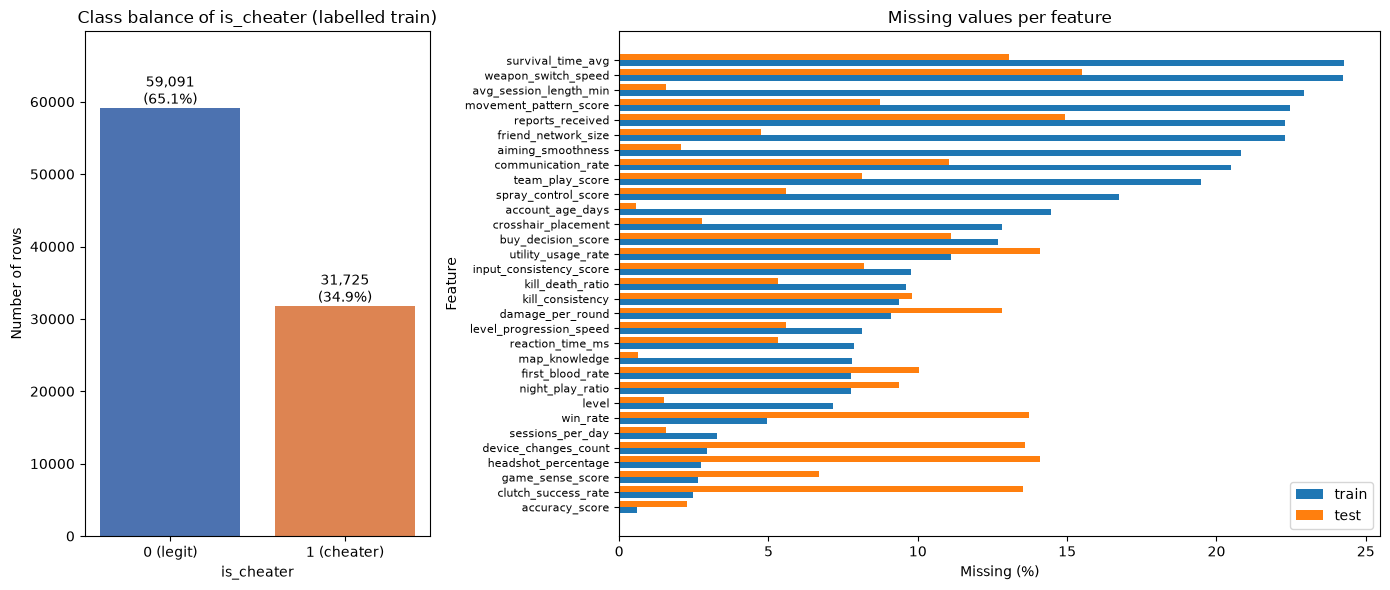

ค่าที่หายไปต่อแถวเฉลี่ย: train 3.71, test 2.48


n_missing (7 = 7+),0,1,2,3,4,5,6,7
rows,1607.0000,6909.0000,14880.0000,20149.0000,19335.0000,13985.0000,8080.0000,5871.0000
cheater_rate,0.3566,0.3449,0.3485,0.3498,0.3481,0.3447,0.3564,0.3582


In [3]:
raw_feats = [c for c in train.columns if c not in ('player_id', TARGET)]
miss = pd.DataFrame({'train': train[raw_feats].isna().mean() * 100,
                     'test': test[raw_feats].isna().mean() * 100}).sort_values('train')

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2.2]})
counts = pd.Series(y).value_counts().sort_index()
axes[0].bar(['0 (legit)', '1 (cheater)'], counts.values, color=['#4C72B0', '#DD8452'])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v:,}\n({v / len(y):.1%})', ha='center', va='bottom')
axes[0].set_title('Class balance of is_cheater (labelled train)')
axes[0].set_xlabel('is_cheater')
axes[0].set_ylabel('Number of rows')
axes[0].set_ylim(0, counts.max() * 1.18)

pos = np.arange(len(miss))
axes[1].barh(pos - 0.2, miss['train'], height=0.4, label='train')
axes[1].barh(pos + 0.2, miss['test'], height=0.4, label='test')
axes[1].set_yticks(pos)
axes[1].set_yticklabels(miss.index, fontsize=8)
axes[1].set_title('Missing values per feature')
axes[1].set_xlabel('Missing (%)')
axes[1].set_ylabel('Feature')
axes[1].legend()
plt.tight_layout()
plt.show()

n_miss = train[raw_feats].isna().sum(axis=1)
rate_by_miss = pd.DataFrame({'rows': n_miss.groupby(n_miss.clip(upper=7)).size(),
                             'cheater_rate': pd.Series(y).groupby(n_miss.clip(upper=7)).mean()})
rate_by_miss.index.name = 'n_missing (7 = 7+)'
print(f'ค่าที่หายไปต่อแถวเฉลี่ย: train {n_miss.mean():.2f}, test {test[raw_feats].isna().sum(axis=1).mean():.2f}')
rate_by_miss.T

ผู้โกงมีประมาณ 35% ของแถวที่มี label จึงไม่สมดุลมาก แต่เพราะ F2 เน้น recall ของแต่ละคลาส threshold ที่ดีที่สุดจะต่ำกว่า 0.5 อย่างชัดเจน

ทุกฟีเจอร์มีค่าหายไปบางส่วน และ test มีค่าที่หายไปน้อยกว่า train (เช่น `crosshair_placement`) แต่สัดส่วนผู้โกงแทบไม่เปลี่ยนตามจำนวนค่าที่หายไปต่อแถว แปลว่าค่าที่หายไปไม่ได้บอกอะไรเกี่ยวกับ label จึงไม่ต้อง impute และปล่อย NaN ให้ LightGBM, XGBoost และ CatBoost จัดการเองได้ (เก็บจำนวนค่าที่หายไปเป็นฟีเจอร์ `n_missing` ไว้ด้วย)

### หลักฐานของ box rule: ปลายช่วงของฟีเจอร์

จากการทดลองพบว่า label ใน train มีลักษณะเหมือนถูกสร้างด้วยกฎที่ปลายช่วงของบางฟีเจอร์ ผู้โกงทุกคนใน train มีค่าอยู่ในช่วงจำกัดของ 6 ฟีเจอร์ด้านล่าง กราฟแสดงสัดส่วนผู้โกงในแต่ละช่วงค่า เส้นประสีแดงคือค่าต่ำสุดและสูงสุดของฟีเจอร์นั้นในกลุ่มผู้โกงของ train

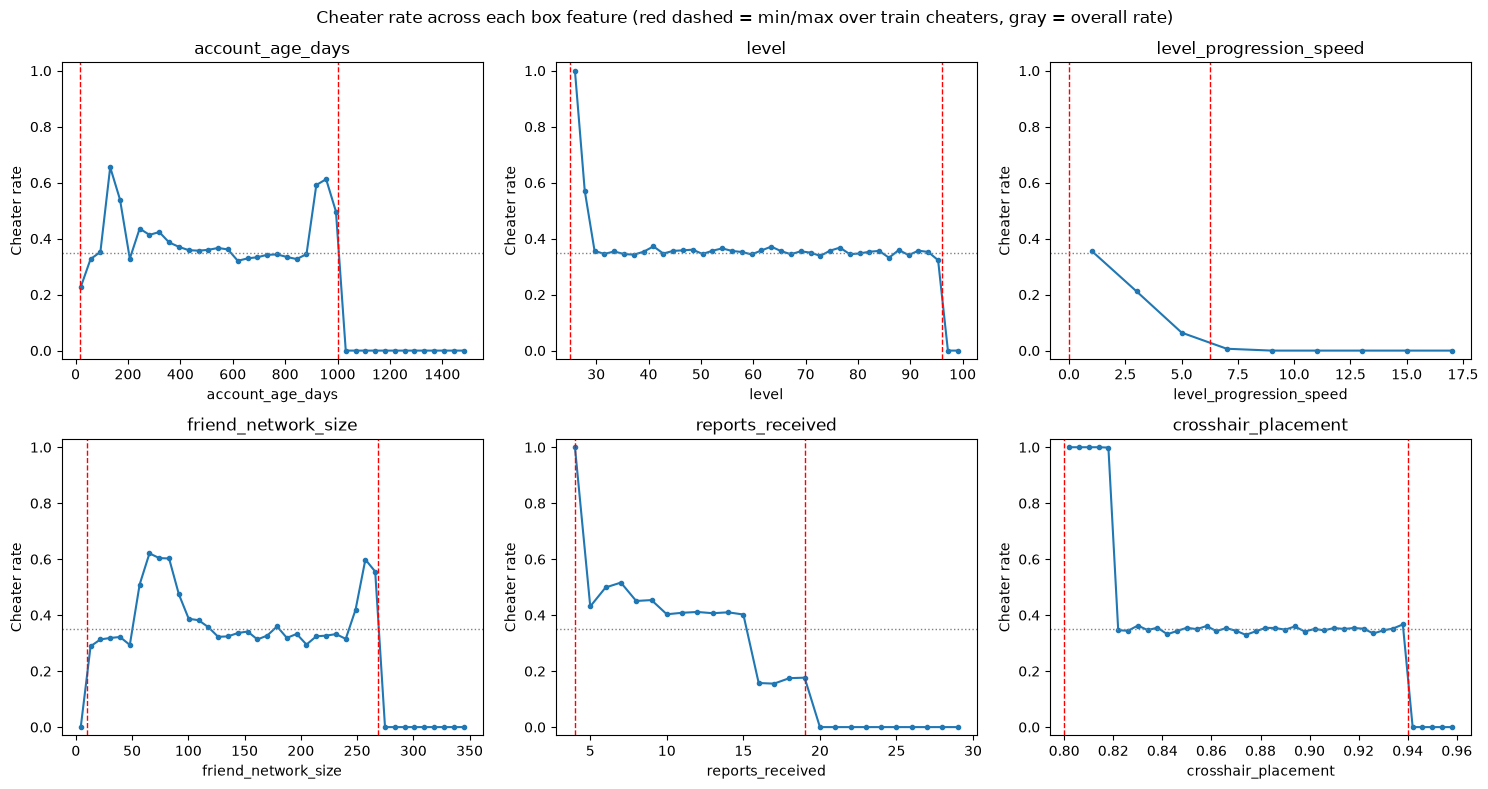

,lo (min ของผู้โกง),hi (max ของผู้โกง),แถว train ที่อยู่นอกช่วง (%)
account_age_days,15.0119,999.9986,7.9083
level,25.0057,95.9969,3.3827
level_progression_speed,0.0044,6.2549,0.6772
friend_network_size,10.0000,269.0000,6.5000
reports_received,4.0000,19.0000,8.3278
crosshair_placement,0.8000,0.9400,8.0922


In [4]:
BOX = ['account_age_days', 'level', 'level_progression_speed',
       'friend_network_size', 'reports_received', 'crosshair_placement']
cheaters = train[y == 1]
box_lo, box_hi = cheaters[BOX].min(), cheaters[BOX].max()   # ใช้เฉพาะผู้โกงใน train

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), BOX):
    v = train[c]
    if c == 'reports_received':
        grp = pd.Series(y).groupby(v.values)
    else:
        edges = np.linspace(v.min(), v.max(), 41)
        mids = (edges[:-1] + edges[1:]) / 2
        idx = np.clip(np.searchsorted(edges, v.values, side='right') - 1, 0, len(mids) - 1)
        grp = pd.Series(y).groupby(np.where(v.isna(), np.nan, mids[idx]))
    stat = grp.agg(['mean', 'size'])
    stat = stat[stat['size'] >= 30]
    ax.plot(stat.index, stat['mean'], marker='o', ms=3)
    ax.axvline(box_lo[c], color='red', ls='--', lw=1)
    ax.axvline(box_hi[c], color='red', ls='--', lw=1)
    ax.axhline(y.mean(), color='gray', ls=':', lw=1)
    ax.set_title(c)
    ax.set_xlabel(c)
    ax.set_ylabel('Cheater rate')
    ax.set_ylim(-0.03, 1.03)
fig.suptitle('Cheater rate across each box feature (red dashed = min/max over train cheaters, gray = overall rate)')
plt.tight_layout()
plt.show()

pd.DataFrame({'lo (min ของผู้โกง)': box_lo, 'hi (max ของผู้โกง)': box_hi,
              'แถว train ที่อยู่นอกช่วง (%)': [((train[c] < box_lo[c]) | (train[c] > box_hi[c])).mean() * 100 for c in BOX]})

ในช่วงกลางของแต่ละฟีเจอร์ สัดส่วนผู้โกงใกล้กับค่าเฉลี่ยรวม (ประมาณ 35%) แต่ที่ปลายช่วงจะเปลี่ยนเป็น 0 หรือ 1 อย่างฉับพลัน เช่น `reports_received` เท่ากับ 4 เป็นผู้โกงทั้งหมด และตั้งแต่ 20 ขึ้นไปไม่มีผู้โกงเลย ส่วน `crosshair_placement` ที่ต่ำมากเกือบทั้งหมดเป็นผู้โกง พฤติกรรมแบบนี้ทำให้เกิด box rule ในขั้นตอนหลังโมเดล คือแถวที่อยู่นอกช่วงของผู้โกงใน train ในฟีเจอร์ใดฟีเจอร์หนึ่งให้ความน่าจะเป็นเป็น 0

## การเตรียมข้อมูลและฟีเจอร์

ใช้ทุกคอลัมน์ตัวเลขยกเว้น `player_id` และ label แล้วเพิ่มฟีเจอร์แบบ row-wise 5 ตัว ซึ่งคำนวณจากค่าในแถวเดียวกันเท่านั้น จึงไม่มีการเรียนรู้ค่าใดจาก test

| ฟีเจอร์ | สูตร | เหตุผล |
|---|---|---|
| `n_missing` | จำนวนค่า NaN ในแถว | เก็บรูปแบบค่าที่หายไปไว้ให้โมเดล |
| `hs_x_acc` | `headshot_percentage * accuracy_score` | ผู้โกงมักแม่นทั้งสองด้านพร้อมกัน |
| `kd_per_level` | `kill_death_ratio / (level + 1)` | ฝีมือสูงผิดปกติเมื่อเทียบกับเลเวล |
| `reports_per_day` | `reports_received / (account_age_days + 1)` | ความถี่ที่ถูกรายงานเทียบกับอายุบัญชี |
| `react_x_acc` | `reaction_time_ms / (accuracy_score + 1e-3)` | ตอบสนองเร็วและแม่นในเวลาเดียวกัน |

ฟีเจอร์ถูกสร้างแยกกันในแต่ละ DataFrame (train และ test) และไม่ทำการ impute หรือ scale เพราะโมเดลต้นไม้ไม่ต้องการ จากการทดลอง การเพิ่มฟีเจอร์อื่น ๆ ให้ผลต่างไม่เกิน 0.001 ซึ่งอยู่ในระดับ noise

In [5]:
FEATS = [c for c in train.columns if c not in ('player_id', TARGET) and not c.startswith('random_metric')]


def add_features(df):
    X = df[FEATS].copy()
    X['n_missing'] = X.isna().sum(axis=1)
    X['hs_x_acc'] = X['headshot_percentage'] * X['accuracy_score']
    X['kd_per_level'] = X['kill_death_ratio'] / (X['level'] + 1)
    X['reports_per_day'] = X['reports_received'] / (X['account_age_days'] + 1)
    X['react_x_acc'] = X['reaction_time_ms'] / (X['accuracy_score'] + 1e-3)
    return X


X = add_features(train)
Xt = add_features(test)
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in X.columns)
print(f'X {X.shape}, Xt {Xt.shape}')

X (90816, 36), Xt (25889, 36)


## โมเดล

ใช้ gradient boosting 3 ชนิด ซึ่งให้ผลใกล้เคียงกันแต่ผิดพลาดต่างกันเล็กน้อย การรวมกันจึงช่วยลด variance ทุกโมเดลใช้ early stopping 200 รอบบนส่วน validation ของ fold นั้น และกำหนด seed ทั้งการแบ่ง fold และตัวโมเดล

| โมเดล | hyperparameter หลัก |
|---|---|
| LightGBM | `binary`, learning_rate 0.03, num_leaves 63, min_child_samples 40, subsample 0.8 (freq 1), colsample_bytree 0.6, reg_lambda 1 |
| XGBoost | `binary:logistic`, eta 0.03, max_depth 7, min_child_weight 5, subsample 0.8, colsample_bytree 0.6, `hist`, ทำนายด้วย `iteration_range` ถึง best_iteration + 1 |
| CatBoost | `Logloss`, iterations 10000, learning_rate 0.05, depth 7, od_type `Iter`, od_wait 200 |

การทดลองก่อนหน้าพบว่าโมเดลที่ซับซ้อนน้อยกว่า (เช่น additive model) ได้คะแนนต่ำกว่าชัดเจน แสดงว่า interaction ระหว่างฟีเจอร์มีความสำคัญ จึงใช้ต้นไม้ที่ลึกพอสมควร

In [6]:
def fit_predict(model, seed, Xtr, ytr, Xva, yva, Xte):
    if model == 'lgb':
        p = dict(objective='binary', learning_rate=0.03, num_leaves=63, min_child_samples=40, subsample=0.8,
                 subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0, verbose=-1, n_jobs=N_JOBS, seed=seed)
        m = lgb.train(p, lgb.Dataset(Xtr, ytr), 10000, valid_sets=[lgb.Dataset(Xva, yva)],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
        return m.predict(Xva), m.predict(Xte)
    if model == 'xgb':
        p = dict(objective='binary:logistic', eta=0.03, max_depth=7, min_child_weight=5, subsample=0.8,
                 colsample_bytree=0.6, tree_method='hist', nthread=N_JOBS, seed=seed)
        dtr, dva = xgb.DMatrix(Xtr, ytr), xgb.DMatrix(Xva, yva)
        m = xgb.train(p, dtr, 10000, evals=[(dva, 'va')], early_stopping_rounds=200, verbose_eval=False)
        it = (0, m.best_iteration + 1)
        return m.predict(dva, iteration_range=it), m.predict(xgb.DMatrix(Xte), iteration_range=it)
    if model == 'cat':
        m = CatBoostClassifier(loss_function='Logloss', iterations=10000, learning_rate=0.05, depth=7,
                               random_seed=seed, thread_count=N_JOBS, od_type='Iter', od_wait=200,
                               verbose=False, allow_writing_files=False)
        m.fit(Xtr, ytr, eval_set=(Xva, yva))
        return m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]
    raise ValueError(model)

## การตรวจสอบด้วย Cross-validation

แต่ละ seed ใช้ `StratifiedKFold(5, shuffle=True, random_state=seed)` ทั้ง 3 โมเดลใน seed เดียวกันใช้ fold ชุดเดียวกัน ความน่าจะเป็น OOF ได้จากโมเดลที่ไม่เคยเห็นแถวนั้นตอนเทรน ส่วนความน่าจะเป็นของ test คือค่าเฉลี่ยของโมเดลทั้ง 5 fold ทุกการ fit ใช้เฉพาะส่วน train ของ fold เท่านั้น (ขั้นตอนนี้ใช้เวลาประมาณ 40 ถึง 60 นาทีบนเครื่อง 18 cores)

In [7]:
oof, test_pred = {}, {}
t_start = time.time()
for seed in SEEDS:
    folds = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y))
    for model in MODELS:
        t0 = time.time()
        name = f'{model}_s{seed}'
        o, tp = np.zeros(len(X)), np.zeros(len(Xt))
        for tr_i, va_i in folds:
            pv, pt = fit_predict(model, seed, X.iloc[tr_i], y[tr_i], X.iloc[va_i], y[va_i], Xt)
            o[va_i] = pv
            tp += pt / len(folds)
        oof[name], test_pred[name] = o, tp
        print(f'{name:<8} macro F2 @0.37 = {macro_f2(y, o, 0.37):.4f}   ({(time.time() - t0) / 60:.1f} นาที)')
print(f'เวลาเทรนทั้งหมด {(time.time() - t_start) / 60:.1f} นาที')

lgb_s42  macro F2 @0.37 = 0.7768   (1.2 นาที)


xgb_s42  macro F2 @0.37 = 0.7764   (4.2 นาที)


cat_s42  macro F2 @0.37 = 0.7765   (4.4 นาที)


lgb_s1   macro F2 @0.37 = 0.7775   (2.5 นาที)


xgb_s1   macro F2 @0.37 = 0.7757   (2.5 นาที)


cat_s1   macro F2 @0.37 = 0.7769   (4.3 นาที)


... (2 outputs left out)

cat_s2   macro F2 @0.37 = 0.7771   (4.6 นาที)


lgb_s3   macro F2 @0.37 = 0.7776   (3.3 นาที)


xgb_s3   macro F2 @0.37 = 0.7782   (3.6 นาที)


cat_s3   macro F2 @0.37 = 0.7771   (4.0 นาที)
เวลาเทรนทั้งหมด 39.7 นาที


,model,seed,AUC,macro F2 @0.37,best macro F2,best threshold
0,lgb,42,0.8904,0.7768,0.7787,0.39
1,xgb,42,0.8897,0.7764,0.7773,0.38
2,cat,42,0.8890,0.7765,0.7769,0.38
3,lgb,1,0.8902,0.7775,0.7784,0.39
4,xgb,1,0.8892,0.7757,0.7773,0.39
5,cat,1,0.8891,0.7769,0.7773,0.40
6,lgb,2,0.8906,0.7782,0.7783,0.38
7,xgb,2,0.8898,0.7770,0.7772,0.38
8,cat,2,0.8887,0.7771,0.7771,0.38
9,lgb,3,0.8908,0.7776,0.7782,0.38


,AUC,macro F2 @0.37,best macro F2
model,,,
cat,0.8890,0.7769,0.7771
lgb,0.8905,0.7775,0.7784
xgb,0.8898,0.7768,0.7775


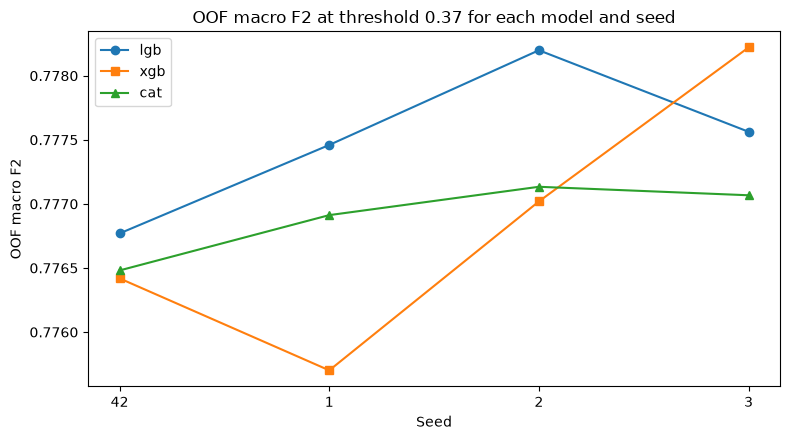

In [8]:
ths_wide = np.round(np.arange(0.05, 0.95, 0.01), 2)
rows = []
for name, o in oof.items():
    scores = [macro_f2(y, o, t) for t in ths_wide]
    model, seed = name.split('_s')
    rows.append({'model': model, 'seed': int(seed), 'AUC': roc_auc_score(y, o),
                 'macro F2 @0.37': macro_f2(y, o, 0.37),
                 'best macro F2': max(scores), 'best threshold': ths_wide[int(np.argmax(scores))]})
per_model = pd.DataFrame(rows)
display(per_model)
display(per_model.groupby('model')[['AUC', 'macro F2 @0.37', 'best macro F2']].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
for m, mk in zip(MODELS, ['o', 's', '^']):
    d = per_model[per_model['model'] == m]
    ax.plot(d['seed'].astype(str), d['macro F2 @0.37'], marker=mk, ls='-', label=m)
ax.set_title('OOF macro F2 at threshold 0.37 for each model and seed')
ax.set_xlabel('Seed')
ax.set_ylabel('OOF macro F2')
ax.legend()
plt.tight_layout()
plt.show()

ตารางแสดงคะแนน OOF ของแต่ละโมเดลทั้ง 12 ตัว คะแนนของ 3 ชนิดโมเดลและ 4 seed อยู่ในช่วงแคบมาก ซึ่งบอกว่าข้อมูลถูกใช้ประโยชน์จนใกล้ขีดจำกัดแล้ว ความต่างระหว่าง seed เกิดจากการสุ่มแบ่ง fold และการสุ่มภายในโมเดล การเฉลี่ยหลาย seed จึงช่วยให้ผลนิ่งขึ้น

## การรวมโมเดล

รวมความน่าจะเป็นของทั้ง 12 โมเดลด้วยค่าเฉลี่ยธรรมดา (ไม่ใช้น้ำหนัก) ทั้งใน OOF และ test เพราะการหาน้ำหนักบน OOF เสี่ยงต่อการ overfit และไม่ได้คะแนนเพิ่มอย่างมีนัยสำคัญในการทดลอง

In [9]:
oof_blend = np.mean([oof[k] for k in oof], axis=0)
test_blend = np.mean([test_pred[k] for k in test_pred], axis=0)
print(f'Blend {len(oof)} โมเดล: AUC {roc_auc_score(y, oof_blend):.4f}, OOF macro F2 @0.37 = {macro_f2(y, oof_blend, 0.37):.4f}')
print(f'โมเดลเดี่ยวที่ดีที่สุด @0.37 = {per_model["macro F2 @0.37"].max():.4f}')
print(f'ความน่าจะเป็นเฉลี่ย: OOF {oof_blend.mean():.3f}, test {test_blend.mean():.3f}')

Blend 12 โมเดล: AUC 0.8927, OOF macro F2 @0.37 = 0.7806
โมเดลเดี่ยวที่ดีที่สุด @0.37 = 0.7782
ความน่าจะเป็นเฉลี่ย: OOF 0.348, test 0.348


## Box rule

ช่วง `[lo, hi]` ของทั้ง 6 ฟีเจอร์คำนวณจากผู้โกงที่มี label ใน train เท่านั้น ไม่ได้ใช้ข้อมูลจาก test ในการกำหนดช่วง แถวที่มีค่าอยู่นอกช่วงในฟีเจอร์ใดก็ตามจะได้ความน่าจะเป็น 0 ส่วนค่า NaN ถือว่าอยู่ในช่วง ใช้กฎเดียวกันกับทั้ง OOF และ test

ข้อควรระวังคือ ใน OOF ช่วงถูกคำนวณจากผู้โกงทุกคนใน train รวมถึงแถวใน fold ที่กำลังประเมิน ผู้โกงใน train จึงไม่มีทางอยู่นอกช่วงตามนิยาม ผลบวกบน OOF อาจมองในแง่ดีเกินจริงเล็กน้อย แต่กฎนี้เปลี่ยนเฉพาะแถวที่โมเดลให้ความน่าจะเป็นต่ำอยู่แล้วเกือบทั้งหมด จึงมีผลต่อคำตอบน้อยมาก

In [10]:
def outside_box(df):
    out = np.zeros(len(df), bool)
    for c in BOX:
        out |= ((df[c] < box_lo[c]) | (df[c] > box_hi[c])).fillna(False).values
    return out


out_tr, out_te = outside_box(train), outside_box(test)
oof_box = np.where(out_tr, 0.0, oof_blend)
test_box = np.where(out_te, 0.0, test_blend)

print(f'แถวนอก box: train {out_tr.mean():.2%} (ผู้โกงนอก box {out_tr[y == 1].sum()} คน), test {out_te.mean():.2%}')
print(f'สัดส่วนผู้โกงใน train ภายใน box {y[~out_tr].mean():.3f}, นอก box {y[out_tr].mean():.3f}')
print(f'ความน่าจะเป็นสูงสุดของ blend ในแถว test ที่อยู่นอก box: {test_blend[out_te].max():.3f}')
box_table = pd.DataFrame({'threshold': [0.37, 0.38, 0.39]})
box_table['OOF macro F2 ก่อน box'] = [macro_f2(y, oof_blend, t) for t in box_table['threshold']]
box_table['OOF macro F2 หลัง box'] = [macro_f2(y, oof_box, t) for t in box_table['threshold']]
box_table['แถว test ที่เปลี่ยน'] = [int(np.sum((test_blend > t) & out_te)) for t in box_table['threshold']]
box_table

แถวนอก box: train 26.31% (ผู้โกงนอก box 0 คน), test 28.82%
สัดส่วนผู้โกงใน train ภายใน box 0.474, นอก box 0.000
ความน่าจะเป็นสูงสุดของ blend ในแถว test ที่อยู่นอก box: 0.998


,threshold,OOF macro F2 ก่อน box,OOF macro F2 หลัง box,แถว test ที่เปลี่ยน
0,0.37,0.7806,0.7808,6
1,0.38,0.7805,0.7807,5
2,0.39,0.7805,0.7806,4


แถวที่อยู่นอก box แทบไม่มีผู้โกงเลย และโมเดลให้ความน่าจะเป็นต่ำกับแถวเหล่านี้อยู่แล้วเกือบทั้งหมด box rule จึงเพิ่มคะแนน OOF ได้เล็กน้อยและเปลี่ยนคำตอบใน test เพียงไม่กี่แถว (เฉพาะแถวที่โมเดลให้ค่าสูงกว่า threshold ทั้งที่อยู่นอกช่วงของผู้โกงทั้งหมดใน train)

## การปรับ threshold

สแกน threshold ตั้งแต่ 0.30 ถึง 0.47 (ทีละ 0.01) บน OOF หลังใช้ box rule แล้วเลือกค่าที่ให้ macro F2 สูงสุด ถ้าค่าที่ดีที่สุดไม่ใช่ 0.37 แต่คะแนนที่ 0.37 ต่างจากค่าที่ดีที่สุดไม่เกิน 0.0005 จะคงใช้ 0.37 ซึ่งเป็นค่าที่ส่งจริง เพราะความต่างระดับนี้อยู่ในระดับ noise ของ CV

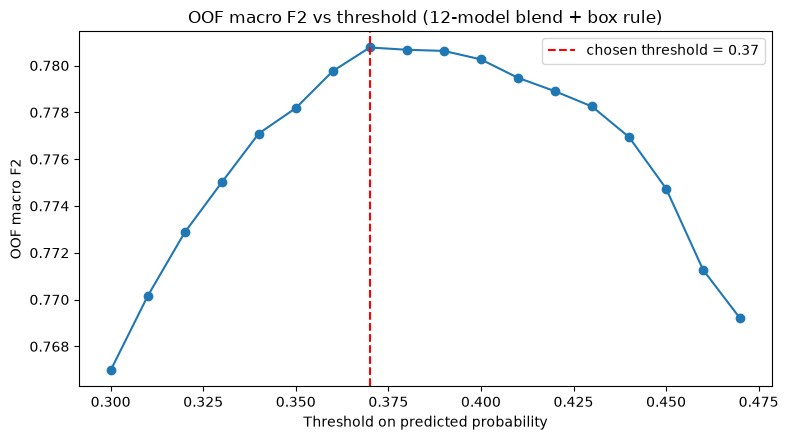

threshold ที่ดีที่สุดบน OOF = 0.37 (macro F2 0.7808), ที่ 0.37 = 0.7808
threshold ที่ใช้ = 0.37


In [11]:
ths = np.round(np.arange(0.30, 0.4701, 0.01), 2)
scan = pd.DataFrame({'threshold': ths, 'macro F2': [macro_f2(y, oof_box, t) for t in ths]})
th_best = float(scan.loc[scan['macro F2'].idxmax(), 'threshold'])
f2_best = scan['macro F2'].max()
TH_SUBMITTED = 0.37
f2_sub = macro_f2(y, oof_box, TH_SUBMITTED)
THRESHOLD = TH_SUBMITTED if f2_best - f2_sub <= 0.0005 else th_best

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(scan['threshold'], scan['macro F2'], marker='o')
ax.axvline(THRESHOLD, color='red', ls='--', label=f'chosen threshold = {THRESHOLD:.2f}')
ax.set_title('OOF macro F2 vs threshold (12-model blend + box rule)')
ax.set_xlabel('Threshold on predicted probability')
ax.set_ylabel('OOF macro F2')
ax.legend()
plt.tight_layout()
plt.show()

print(f'threshold ที่ดีที่สุดบน OOF = {th_best:.2f} (macro F2 {f2_best:.4f}), ที่ 0.37 = {f2_sub:.4f}')
print(f'threshold ที่ใช้ = {THRESHOLD:.2f}')

กราฟมีลักษณะค่อนข้างแบนรอบจุดสูงสุด คะแนนที่ threshold 0.37 ถึง 0.40 ต่างกันไม่เกินประมาณ 0.0005 ดังนั้นการเลือก threshold ในช่วงนี้ไม่ทำให้ผลเปลี่ยนอย่างมีนัยสำคัญ ค่าที่ดีที่สุดบน OOF คือ 0.37 ซึ่งตรงกับค่าที่ใช้ส่งจริง และ threshold ทั้งหมดเลือกจาก OOF ของ train เท่านั้น

## การสร้างไฟล์คำตอบ

แปลงความน่าจะเป็นของ test (หลัง box rule) เป็นคลาสด้วย threshold ที่เลือก แล้วบันทึกเป็น `output/task1_pred.csv` โดยคอลัมน์ `id` เรียงตามลำดับแถวของ test (`ANS00001`, `ANS00002`, ...)

In [12]:
pred = (test_box > THRESHOLD).astype(int)
sub = pd.DataFrame({'id': [f'ANS{i + 1:05d}' for i in range(len(test))], 'task1': pred})
sub.to_csv(OUT_DIR / 'task1_pred.csv', index=False)

print(f'บันทึก output/task1_pred.csv: {len(sub):,} แถว')
print(f'ทำนายเป็นผู้โกง {pred.sum():,} แถว ({pred.mean():.1%}), ไม่โกง {(1 - pred).sum():,} แถว')
print(f'สัดส่วนที่ทำนายเป็นผู้โกงบน OOF ที่ threshold เดียวกัน: {(oof_box > THRESHOLD).mean():.1%}')
sub.head()

บันทึก output/task1_pred.csv: 25,889 แถว
ทำนายเป็นผู้โกง 10,974 แถว (42.4%), ไม่โกง 14,915 แถว
สัดส่วนที่ทำนายเป็นผู้โกงบน OOF ที่ threshold เดียวกัน: 43.0%


,id,task1
0,ANS00001,1
1,ANS00002,1
2,ANS00003,1
3,ANS00004,1
4,ANS00005,0


## สรุป

- โมเดลเดี่ยวทั้ง 12 ตัว (LightGBM, XGBoost, CatBoost อย่างละ 4 seed) ได้ OOF macro F2 ที่ threshold 0.37 อยู่ระหว่าง 0.7757 ถึง 0.7782 และ AUC ประมาณ 0.889 ถึง 0.891
- การเฉลี่ยทั้ง 12 โมเดลเพิ่ม OOF macro F2 เป็น 0.7806 และ box rule ที่สร้างจากช่วงค่าของผู้โกงใน train เพิ่มเป็น 0.7808 โดยเปลี่ยนคำตอบใน test เพียง 6 แถว
- threshold ที่ดีที่สุดบน OOF คือ 0.37 ได้สัดส่วนผู้ที่ถูกทำนายว่าโกงใน test 42.4% ใกล้เคียงกับบน OOF (43.0%)
- คะแนนของโมเดลทุกชนิดและทุก seed อยู่ในช่วงแคบ และการทดลองเพิ่มฟีเจอร์ โมเดลประเภทอื่น หรือการปรับ threshold ละเอียดขึ้นให้ผลต่างอยู่ในระดับ noise แสดงว่า Task 1 ใกล้ขีดจำกัดจาก noise ของข้อมูลแล้ว (ประมาณ 0.78 macro F2) ส่วนที่เหลือของความผิดพลาดมาจากแถวในช่วงกลางของฟีเจอร์ที่สัดส่วนผู้โกงคงที่ประมาณ 35% ซึ่งแยกได้ยากจากข้อมูลที่มี
- ทุกขั้นตอนที่มีการเรียนรู้ (การเทรนโมเดล ช่วงของ box rule และการเลือก threshold) ใช้เฉพาะข้อมูล train ส่วน test ถูกใช้เพื่อทำนายเท่านั้น
